In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import tensorflow as tf

# 15장 RNN과 CNN을 사용한 시퀀스 처리

## 15.3 시계열 예측하기

In [2]:
tf.keras.utils.get_file(
    'ridership.tgz',
    'https://github.com/ageron/data/raw/main/ridership.tgz',
    cache_dir='.',
    extract=True
)

'./datasets/ridership_extracted'

In [3]:
from pathlib import Path

path = Path('datasets/ridership_extracted/ridership/CTA_-_Ridership_-_Daily_Boarding_Totals.csv')
df = pd.read_csv(path, parse_dates=['service_date'])

df.head()

,service_date,day_type,bus,rail_boardings,total_rides
0,2001-01-01,U,297192,126455,423647
1,2001-01-02,W,780827,501952,1282779
2,2001-01-03,W,824923,536432,1361355
3,2001-01-04,W,870021,550011,1420032
4,2001-01-05,W,890426,557917,1448343


In [4]:
df.columns = ['date', 'day_type', 'bus', 'rail', 'total']
df = df.sort_values('date').set_index('date')
df = df.drop('total', axis=1)
df = df.drop_duplicates()

df.head()

,day_type,bus,rail
date,,,
2001-01-01,U,297192,126455
2001-01-02,W,780827,501952
2001-01-03,W,824923,536432
2001-01-04,W,870021,550011
2001-01-05,W,890426,557917


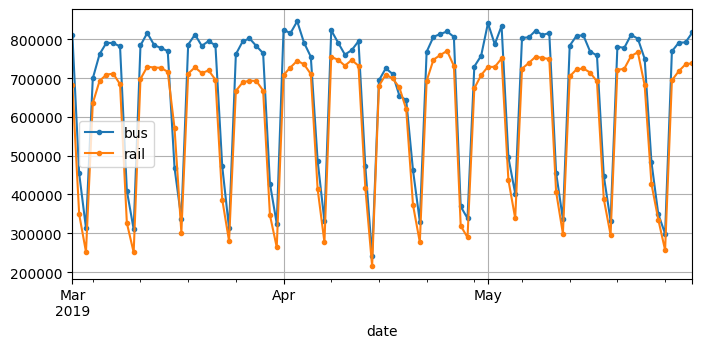

In [5]:
df['2019-03':'2019-05'].plot(grid=True, marker='.', figsize=(8, 3.5))
plt.show()

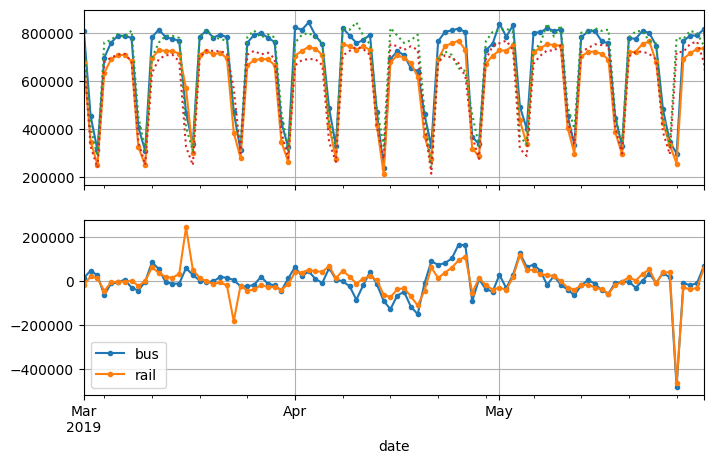

In [6]:
diff_7 = df[['bus', 'rail']].diff(7)['2019-03':'2019-05']

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 5))
df.plot(ax=axs[0], legend=False, marker='.')
df.shift(7).plot(ax=axs[0], grid=True, legend=False, linestyle=':')
diff_7.plot(ax=axs[1], grid=True, marker='.')
axs[0].set_ylim(170_000, 900_000)
plt.show()

In [7]:
list(df.loc['2019-05-25':'2019-05-27']['day_type'])

['A', 'U', 'U']

In [8]:
diff_7.abs().mean()

bus     43915.608696
rail    42143.271739
dtype: float64

In [9]:
targets = df[['bus', 'rail']]['2019-03':'2019-05']
(diff_7 / targets).abs().mean()

bus     0.082938
rail    0.089948
dtype: float64

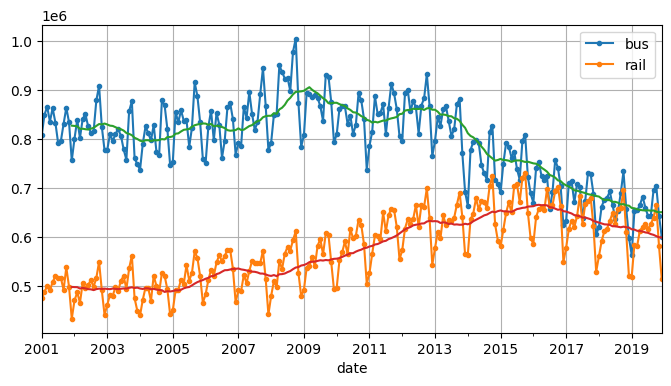

In [10]:
period = slice('2001', '2019')
df_monthly = df.resample('ME').mean(numeric_only=True)
rolling_average_12_months = df_monthly[period].rolling(window=12).mean()

fig, ax = plt.subplots(figsize=(8, 4))
df_monthly[period].plot(ax=ax, marker='.')
rolling_average_12_months.plot(ax=ax, grid=True, legend=False)
plt.show()

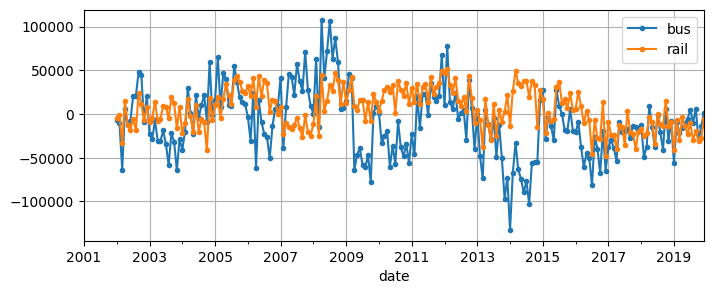

In [11]:
df_monthly.diff(12)[period].plot(grid=True, marker='.', figsize=(8, 3))
plt.show()

### 15.3.1 ARMA 모델

In [12]:
from statsmodels.tsa.arima.model import ARIMA

origin, today = '2019-01-01', '2019-05-31'
rail_series = df.loc[origin:today]['rail'].asfreq('D')
model = ARIMA(rail_series, order=(1, 0, 0), seasonal_order=(0, 1, 1, 7))
model = model.fit()
y_pred = model.forecast()

In [13]:
y_pred.iloc[0]

427758.62629933096

In [14]:
df['rail']['2019-06-01']

379044

In [15]:
df['rail']['2019-05-25']

426932

In [16]:
origin, start_date, end_date = '2019-01-01', '2019-03-01', '2019-05-31'
time_period = pd.date_range(start_date, end_date)
rail_series = df['rail'][origin:end_date].asfreq('D')

y_preds = []
for today in time_period.shift(-1):
    model = ARIMA(rail_series[origin:today],
                  order=(1, 0, 0), seasonal_order=(0, 1, 1, 7))
    model = model.fit()
    y_pred = model.forecast().iloc[0]
    y_preds.append(y_pred)

y_preds = pd.Series(y_preds, index=time_period)
mae = (y_preds - rail_series).abs().mean()
mae

32040.7200972509

In [17]:
(rail_series[time_period] - rail_series[time_period].shift(-7)).abs().mean()

44306.42352941177

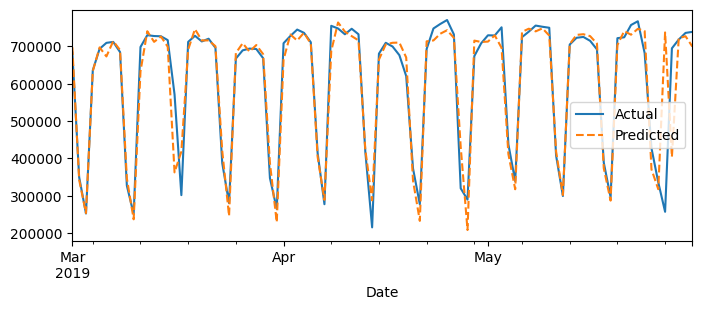

In [18]:
fig, ax = plt.subplots(figsize=(8, 3))
rail_series[time_period].plot(ax=ax, label='Actual', grid=True)
y_preds[time_period].plot(ax=ax, label='Predicted', linestyle='--')
plt.xlabel('Date')
plt.legend()
plt.show()

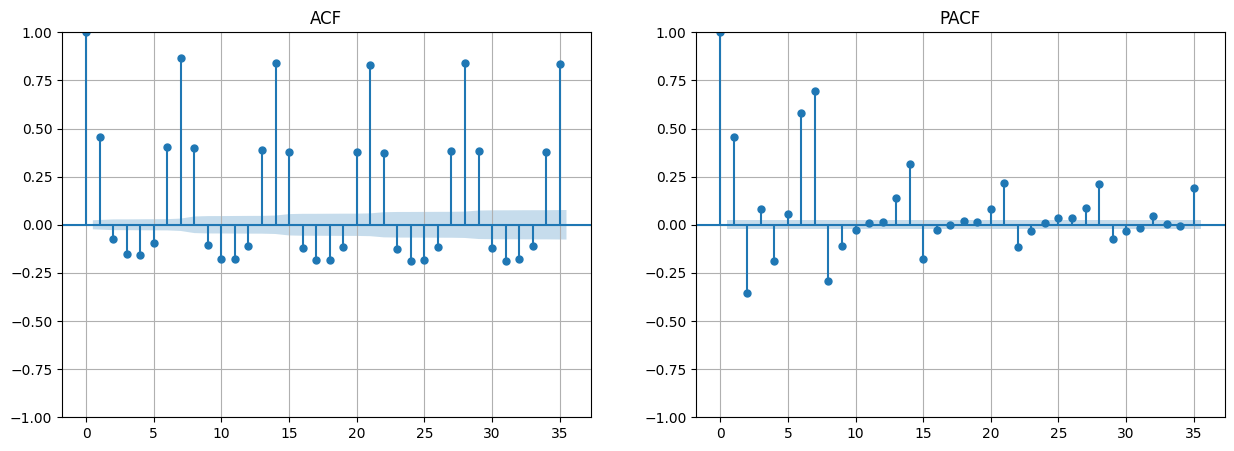

In [19]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
plot_acf(df[period]['rail'], ax=axs[0], lags=35, title='ACF')
axs[0].grid()
plot_pacf(df[period]['rail'], ax=axs[1], lags=35, title='PACF', method='ywm')
axs[1].grid()
plt.show()

### 15.3.2 머신러닝 모델을 위한 데이터 준비하기

In [20]:
my_series = [0, 1, 2, 3, 4, 5]
my_dataset = tf.keras.utils.timeseries_dataset_from_array(
    my_series, targets=my_series[3:], sequence_length=3, batch_size=2)

In [21]:
list(my_dataset)

[(<tf.Tensor: shape=(2, 3), dtype=int32, numpy=
  array([[0, 1, 2],
         [1, 2, 3]], dtype=int32)>,
  <tf.Tensor: shape=(2,), dtype=int32, numpy=array([3, 4], dtype=int32)>),
 (<tf.Tensor: shape=(1, 3), dtype=int32, numpy=array([[2, 3, 4]], dtype=int32)>,
  <tf.Tensor: shape=(1,), dtype=int32, numpy=array([5], dtype=int32)>)]

In [22]:
for window_dataset in tf.data.Dataset.range(6).window(4, shift=1):
    for element in window_dataset:
        print(f'{element}', end=' ')
    print()

0 1 2 3 
1 2 3 4 
2 3 4 5 
3 4 5 
4 5 
5 


In [23]:
dataset = tf.data.Dataset.range(6).window(4, shift=1, drop_remainder=True)
dataset = dataset.flat_map(lambda window_dataset: window_dataset.batch(4))
for window_tensor in dataset:
    print(f'{window_tensor}')

[0 1 2 3]
[1 2 3 4]
[2 3 4 5]


In [24]:
def to_windows(dataset, length):
    dataset = dataset.window(length, shift=1, drop_remainder=True)
    return dataset.flat_map(lambda window_ds: window_ds.batch(length))

In [25]:
dataset = to_windows(tf.data.Dataset.range(6), 4)
dataset = dataset.map(lambda window: (window[:-1], window[-1]))
list(dataset.batch(2))

[(<tf.Tensor: shape=(2, 3), dtype=int64, numpy=
  array([[0, 1, 2],
         [1, 2, 3]])>,
  <tf.Tensor: shape=(2,), dtype=int64, numpy=array([3, 4])>),
 (<tf.Tensor: shape=(1, 3), dtype=int64, numpy=array([[2, 3, 4]])>,
  <tf.Tensor: shape=(1,), dtype=int64, numpy=array([5])>)]

In [26]:
rail_train = df['rail']['2016-01':'2018-12'] / 1e6
rail_valid = df['rail']['2019-01':'2019-05'] / 1e6
rail_test = df['rail']['2019-06':] / 1e6

In [27]:
seq_length = 56
train_ds = tf.keras.utils.timeseries_dataset_from_array(
    rail_train.to_numpy(),
    targets=rail_train[seq_length:],
    sequence_length=seq_length,
    batch_size=32,
    shuffle=True,
    seed=42
)
valid_ds = tf.keras.utils.timeseries_dataset_from_array(
    rail_valid.to_numpy(),
    targets=rail_valid[seq_length:],
    sequence_length=seq_length,
    batch_size=32,
)

### 15.3.3 선형 모델로 예측하기

In [28]:
def fit_and_evaluate(model, train_set, valid_set, learning_rate, epochs=500):
    early_stopping_cb = tf.keras.callbacks.EarlyStopping(
        monitor='val_mae', patience=50, restore_best_weights=True)
    optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)
    model.compile(loss=tf.keras.losses.Huber(), optimizer=optimizer, metrics=['mae'])
    history = model.fit(train_set, epochs=epochs, validation_data=valid_set,
                        callbacks=[early_stopping_cb])
    valid_loss, valid_mae = model.evaluate(valid_set)
    return valid_mae * 1e6

In [29]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(seq_length,)),
    tf.keras.layers.Dense(1)
])

In [30]:
fit_and_evaluate(model, train_ds, valid_ds, 0.02)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1010 - mae: 0.3618 - val_loss: 0.0098 - val_mae: 0.1087
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0086 - mae: 0.0986 - val_loss: 0.0061 - val_mae: 0.0771
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0076 - mae: 0.0927 - val_loss: 0.0075 - val_mae: 0.0911
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0069 - mae: 0.0853 - val_loss: 0.0074 - val_mae: 0.0937
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0063 - mae: 0.0815 - val_loss: 0.0053 - val_mae: 0.0736
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0058 - mae: 0.0773 - val_loss: 0.0056 - val_mae: 0.0744
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0053 - mae: 0.0739 - val_loss: 0.0045 - val_mae: 0.0649
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0051 - mae: 0.0728 - val_loss: 0.0052 - val_mae: 0.0754
Epoch 9/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.004

37886.034697294235

### 15.3.4 간단한 RNN으로 예측하기

In [31]:
tf.random.set_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 1)),
    tf.keras.layers.SimpleRNN(1)
])

In [32]:
fit_and_evaluate(model, train_ds, valid_ds, 0.05)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4702 - mae: 0.8203 - val_loss: 0.0804 - val_mae: 0.3596
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0673 - mae: 0.3182 - val_loss: 0.0610 - val_mae: 0.3004
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0326 - mae: 0.1900 - val_loss: 0.0199 - val_mae: 0.1493
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0197 - mae: 0.1671 - val_loss: 0.0193 - val_mae: 0.1362
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0182 - mae: 0.1598 - val_loss: 0.0175 - val_mae: 0.1394
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0170 - mae: 0.1570 - val_loss: 0.0163 - val_mae: 0.1372
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0160 - mae: 0.1543 - val_loss: 0.0156 - val_mae: 0.1307
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0152 - mae: 0.1529 - val_loss: 0.0145 - val_mae: 0.1309
Epoch 9/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.014

102757.90840387344

In [33]:
tf.random.set_seed(42)

univar_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 1)),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(1)
])

In [34]:
fit_and_evaluate(univar_model, train_ds, valid_ds, 0.05)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0267 - mae: 0.1405 - val_loss: 0.0030 - val_mae: 0.0583
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0042 - mae: 0.0630 - val_loss: 0.0026 - val_mae: 0.0488
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0041 - mae: 0.0619 - val_loss: 0.0022 - val_mae: 0.0409
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0036 - mae: 0.0547 - val_loss: 0.0026 - val_mae: 0.0455
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0038 - mae: 0.0581 - val_loss: 0.0031 - val_mae: 0.0536
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0034 - mae: 0.0531 - val_loss: 0.0021 - val_mae: 0.0365
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0037 - mae: 0.0566 - val_loss: 0.0046 - val_mae: 0.0787
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0034 - mae: 0.0540 - val_loss: 0.0020 - val_mae: 0.0324
Epoch 9/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.003

28318.151831626892

### 15.3.5 심층 RNN으로 예측하기

In [35]:
tf.random.set_seed(42)

deep_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 1)),
    tf.keras.layers.SimpleRNN(32, return_sequences=True),
    tf.keras.layers.SimpleRNN(32, return_sequences=True),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(1)
])

In [36]:
fit_and_evaluate(deep_model, train_ds, valid_ds, 0.01)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0182 - mae: 0.1354 - val_loss: 0.0067 - val_mae: 0.0923
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0052 - mae: 0.0682 - val_loss: 0.0033 - val_mae: 0.0596
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0042 - mae: 0.0590 - val_loss: 0.0022 - val_mae: 0.0421
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0040 - mae: 0.0555 - val_loss: 0.0027 - val_mae: 0.0496
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0042 - mae: 0.0582 - val_loss: 0.0021 - val_mae: 0.0387
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0038 - mae: 0.0565 - val_loss: 0.0029 - val_mae: 0.0531
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0037 - mae: 0.0544 - val_loss: 0.0021 - val_mae: 0.0373
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0038 - mae: 0.0567 - val_loss: 0.0030 - val_mae: 0.0544
Epoch 9/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss:

29961.535707116127

### 15.3.6 다변량 시계열 예측하기

In [37]:
df_mulvar = df[['bus', 'rail']] / 1e6
df_mulvar['next_day_type'] = df[['day_type']].shift(-1)
df_mulvar = pd.get_dummies(df_mulvar)

In [38]:
df_mulvar.head()

,bus,rail,next_day_type_A,next_day_type_U,next_day_type_W
date,,,,,
2001-01-01,0.297192,0.126455,False,False,True
2001-01-02,0.780827,0.501952,False,False,True
2001-01-03,0.824923,0.536432,False,False,True
2001-01-04,0.870021,0.550011,False,False,True
2001-01-05,0.890426,0.557917,True,False,False


In [39]:
mulvar_train = df_mulvar['2016-01':'2018-12']
mulvar_valid = df_mulvar['2019-01':'2019-05']
mulvar_test = df_mulvar['2019-06':]

In [40]:
train_mulvar_ds = tf.keras.utils.timeseries_dataset_from_array(
    mulvar_train.to_numpy(np.float32),
    targets=mulvar_train['rail'][seq_length:],
    sequence_length=seq_length,
    batch_size=32,
    shuffle=True,
    seed=42
)

valid_mulvar_ds = tf.keras.utils.timeseries_dataset_from_array(
    mulvar_valid.to_numpy(np.float32),
    targets=mulvar_valid['rail'][seq_length:],
    sequence_length=seq_length,
    batch_size=32,
)

In [41]:
tf.random.set_seed(42)

mulvar_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(1)
])

In [42]:
fit_and_evaluate(mulvar_model, train_mulvar_ds, valid_mulvar_ds, 0.05)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0281 - mae: 0.1771 - val_loss: 0.0050 - val_mae: 0.0853
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0029 - mae: 0.0571 - val_loss: 0.0019 - val_mae: 0.0522
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0017 - mae: 0.0414 - val_loss: 0.0014 - val_mae: 0.0441
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0015 - mae: 0.0393 - val_loss: 0.0012 - val_mae: 0.0403
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0014 - mae: 0.0371 - val_loss: 0.0011 - val_mae: 0.0367
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0013 - mae: 0.0360 - val_loss: 9.2134e-04 - val_mae: 0.0333
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0014 - mae: 0.0367 - val_loss: 8.0879e-04 - val_mae: 0.0306
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0013 - mae: 0.0363 - val_loss: 8.9101e-04 - val_mae: 0.0328
Epoch 9/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step -

23684.358224272728

In [43]:
bus_naive = mulvar_valid['bus'].shift(7)[seq_length:]
bus_target = mulvar_valid['bus'][seq_length:]
(bus_naive - bus_target).abs().mean() * 1e6

43441.63157894738

In [44]:
train_multask_ds = tf.keras.utils.timeseries_dataset_from_array(
    mulvar_train.to_numpy(np.float32),
    targets=mulvar_train[['bus', 'rail']][seq_length:],
    sequence_length=seq_length,
    batch_size=32,
    shuffle=True,
    seed=42
)

valid_multask_ds = tf.keras.utils.timeseries_dataset_from_array(
    mulvar_valid.to_numpy(np.float32),
    targets=mulvar_valid[['bus', 'rail']][seq_length:],
    sequence_length=seq_length,
    batch_size=32,
)

In [45]:
tf.random.set_seed(42)

multask_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(2)
])

In [46]:
fit_and_evaluate(multask_model, train_multask_ds, valid_multask_ds, 0.02)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0566 - mae: 0.2466 - val_loss: 0.0033 - val_mae: 0.0616
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0036 - mae: 0.0616 - val_loss: 0.0018 - val_mae: 0.0443
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0024 - mae: 0.0486 - val_loss: 0.0015 - val_mae: 0.0394
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0022 - mae: 0.0465 - val_loss: 0.0012 - val_mae: 0.0349
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0020 - mae: 0.0441 - val_loss: 0.0014 - val_mae: 0.0390
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0020 - mae: 0.0437 - val_loss: 0.0011 - val_mae: 0.0332
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0018 - mae: 0.0423 - val_loss: 9.9036e-04 - val_mae: 0.0326
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0018 - mae: 0.0420 - val_loss: 0.0015 - val_mae: 0.0437
Epoch 9/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0

25111.401453614235

In [47]:
Y_preds_valid = multask_model.predict(valid_multask_ds)
for idx, name in enumerate(['bus', 'rail']):
    mae = tf.keras.metrics.MAE(mulvar_valid[name][seq_length:], Y_preds_valid[:, idx]) * 1e6
    print(f'{name}\t{mae}')

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
bus	25658.740234375
rail	24564.060546875


### 15.3.7 여러 타임 스텝 앞 예측하기

In [48]:
X = rail_valid.to_numpy()[np.newaxis, :seq_length, np.newaxis]
for step_ahead in range(14):
    y_pred_one = univar_model.predict(X)
    X = np.concatenate([X, y_pred_one.reshape(1, 1, 1)], axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


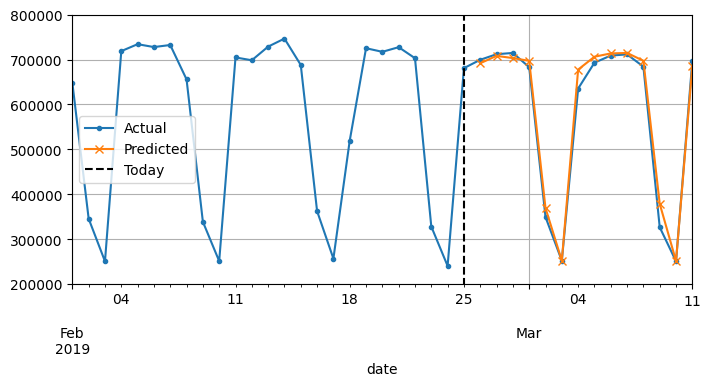

In [49]:
Y_pred = pd.Series(X[0, -14:, 0], index=pd.date_range("2019-02-26", "2019-03-11"))

fig, ax = plt.subplots(figsize=(8, 3.5))
(1e6 * rail_valid)['2019-02-01':'2019-03-11'].plot(ax=ax, marker='.', label='Actual')
(1e6 * Y_pred).plot(ax=ax, marker='x', label='Predicted', grid=True)
ax.vlines('2019-02-25', 0, 1e6, color='k', linestyle='--', label='Today')
ax.set_ylim([200_000, 800_000])
ax.legend()
plt.show()

In [50]:
def split_inputs_and_targets(mulvar_series, ahead=14, target_col=1):
    return mulvar_series[:, :-ahead], mulvar_series[:, -ahead:, target_col]

ahead_train_ds = tf.keras.utils.timeseries_dataset_from_array(
    mulvar_train.to_numpy(np.float32),
    targets=None,
    sequence_length=seq_length + 14,
    batch_size=32,
    shuffle=True,
    seed=42
).map(split_inputs_and_targets)

ahead_valid_ds = tf.keras.utils.timeseries_dataset_from_array(
    mulvar_valid.to_numpy(np.float32),
    targets=None,
    sequence_length=seq_length + 14,
    batch_size=32
).map(split_inputs_and_targets)

In [51]:
tf.random.set_seed(42)

ahead_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
    tf.keras.layers.SimpleRNN(32),
    tf.keras.layers.Dense(14)
])

In [52]:
fit_and_evaluate(ahead_model, ahead_train_ds, ahead_valid_ds, 0.02)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0621 - mae: 0.2600 - val_loss: 0.0183 - val_mae: 0.1508
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0163 - mae: 0.1477 - val_loss: 0.0145 - val_mae: 0.1282
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0139 - mae: 0.1358 - val_loss: 0.0122 - val_mae: 0.1222
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0127 - mae: 0.1302 - val_loss: 0.0113 - val_mae: 0.1164
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0120 - mae: 0.1256 - val_loss: 0.0108 - val_mae: 0.1123
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0114 - mae: 0.1220 - val_loss: 0.0101 - val_mae: 0.1089
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0108 - mae: 0.1182 - val_loss: 0.0093 - val_mae: 0.1060
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0103 - mae: 0.1153 - val_loss: 0.0088 - val_mae: 0.1031
Epoch 9/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.009

33396.01308107376

In [53]:
X = mulvar_valid.to_numpy(np.float32)[np.newaxis, :seq_length]
Y_pred = ahead_model.predict(X)
Y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


array([[0.7217732 , 0.7235737 , 0.7191386 , 0.7123918 , 0.38395336,
        0.27379268, 0.66385776, 0.71424574, 0.7052591 , 0.72375005,
        0.7249358 , 0.3749144 , 0.31694663, 0.681904  ]], dtype=float32)

### 15.3.8 시퀀스-투-시퀀스 모델로 예측하기

In [54]:
my_series = tf.data.Dataset.range(7)
dataset = to_windows(to_windows(my_series, 3), 4)
list(dataset)

[<tf.Tensor: shape=(4, 3), dtype=int64, numpy=
 array([[0, 1, 2],
        [1, 2, 3],
        [2, 3, 4],
        [3, 4, 5]])>,
 <tf.Tensor: shape=(4, 3), dtype=int64, numpy=
 array([[1, 2, 3],
        [2, 3, 4],
        [3, 4, 5],
        [4, 5, 6]])>]

In [55]:
dataset = dataset.map(lambda S: (S[:, 0], S[:, 1:]))
list(dataset)

[(<tf.Tensor: shape=(4,), dtype=int64, numpy=array([0, 1, 2, 3])>,
  <tf.Tensor: shape=(4, 2), dtype=int64, numpy=
  array([[1, 2],
         [2, 3],
         [3, 4],
         [4, 5]])>),
 (<tf.Tensor: shape=(4,), dtype=int64, numpy=array([1, 2, 3, 4])>,
  <tf.Tensor: shape=(4, 2), dtype=int64, numpy=
  array([[2, 3],
         [3, 4],
         [4, 5],
         [5, 6]])>)]

In [56]:
def to_seq2seq_dataset(series, seq_length=56, ahead=14, target_col=1,
                       batch_size=32, shuffle=False, seed=None):
    ds = to_windows(tf.data.Dataset.from_tensor_slices(series.to_numpy(np.float32)), ahead + 1)
    ds = to_windows(ds, seq_length).map(lambda S: (S[:, 0], S[:, 1:, target_col]))
    if shuffle:
        ds = ds.shuffle(8 * batch_size, seed=seed)
    return ds.batch(batch_size)

In [57]:
seq2seq_train = to_seq2seq_dataset(mulvar_train, shuffle=True, seed=42)
seq2seq_valid = to_seq2seq_dataset(mulvar_valid)

In [58]:
tf.random.set_seed(42)

seq2seq_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
    tf.keras.layers.SimpleRNN(32, return_sequences=True),
    tf.keras.layers.Dense(14)
])

In [59]:
fit_and_evaluate(seq2seq_model, seq2seq_train, seq2seq_valid, 0.1)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0654 - mae: 0.2580 - val_loss: 0.0143 - val_mae: 0.1283
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0086 - mae: 0.0964 - val_loss: 0.0073 - val_mae: 0.0825
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0061 - mae: 0.0768 - val_loss: 0.0061 - val_mae: 0.0739
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0054 - mae: 0.0708 - val_loss: 0.0057 - val_mae: 0.0703
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0049 - mae: 0.0666 - val_loss: 0.0053 - val_mae: 0.0663
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0046 - mae: 0.0635 - val_loss: 0.0049 - val_mae: 0.0625
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0045 - mae: 0.0623 - val_loss: 0.0051 - val_mae: 0.0653
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0043 - mae: 0.0607 - val_loss: 0.0047 - val_mae: 0.0605
Epoch 9/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.004

47112.94546723366

In [60]:
X = mulvar_valid.to_numpy(np.float32)[np.newaxis, :seq_length]
y_pred_14 = seq2seq_model.predict(X)[0, -1]
y_pred_14

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


array([0.7173792 , 0.72783875, 0.7264532 , 0.68148977, 0.36270592,
       0.27046368, 0.64840704, 0.7095884 , 0.7320173 , 0.736498  ,
       0.69100463, 0.37449646, 0.2892525 , 0.6654462 ], dtype=float32)

In [61]:
Y_pred_valid = seq2seq_model.predict(seq2seq_valid)
for ahead in range(14):
    preds = pd.Series(Y_pred_valid[:-1, -1, ahead],
                      index=mulvar_valid.index[56 + ahead : -14 + ahead])
    mae = (preds - mulvar_valid['rail']).abs().mean() * 1e6
    print(f"MAE for +{ahead + 1}: {mae:,.0f}")

1/Unknown 0s 59ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
MAE for +1: 25,259
MAE for +2: 29,578
MAE for +3: 31,801
MAE for +4: 31,221
MAE for +5: 32,408
MAE for +6: 34,097
MAE for +7: 35,558
MAE for +8: 35,712
MAE for +9: 32,931
MAE for +10: 32,675
MAE for +11: 35,252
MAE for +12: 36,720
MAE for +13: 36,971
MAE for +14: 35,415


## 15.4 긴 시퀀스 다루기

### 15.4.1 불안정한 그레이디언트 문제와 싸우기

In [62]:
class LNSimpleRNNCell(tf.keras.layers.Layer):
    def __init__(self, units, activation='tanh', **kwargs):
        super().__init__(**kwargs)
        self.state_size = units
        self.output_size = units
        self.simple_rnn_cell = tf.keras.layers.SimpleRNNCell(units, activation=None)
        self.layer_norm = tf.keras.layers.LayerNormalization()
        self.activation = tf.keras.activations.get(activation)

    def build(self, input_shape):
        self.simple_rnn_cell.build(input_shape)
        self.layer_norm.build((None, self.state_size))
        super().build(input_shape)

    def call(self, inputs, states):
        outputs, new_states = self.simple_rnn_cell(inputs, states)
        norm_outputs = self.activation(self.layer_norm(outputs))
        return norm_outputs, [norm_outputs]

In [63]:
tf.random.set_seed(42)

custom_ln_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
    tf.keras.layers.RNN(LNSimpleRNNCell(32), return_sequences=True),
    tf.keras.layers.Dense(14)
])

In [64]:
fit_and_evaluate(custom_ln_model, seq2seq_train, seq2seq_valid, 0.1, epochs=5)

Epoch 1/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1063 - mae: 0.3200 - val_loss: 0.0150 - val_mae: 0.1340
Epoch 2/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0089 - mae: 0.0995 - val_loss: 0.0078 - val_mae: 0.0899
Epoch 3/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0061 - mae: 0.0795 - val_loss: 0.0069 - val_mae: 0.0840
Epoch 4/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0056 - mae: 0.0743 - val_loss: 0.0063 - val_mae: 0.0787
Epoch 5/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0053 - mae: 0.0711 - val_loss: 0.0056 - val_mae: 0.0724
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0056 - mae: 0.0724


72410.11410951614

In [65]:
class MyRNN(tf.keras.layers.Layer):
    def __init__(self, cell, return_sequences=False, **kwargs):
        super().__init__(**kwargs)
        self.cell = cell
        self.return_sequences = return_sequences

    def get_initial_state(self, inputs):
        try:
            return self.cell.get_initial_state(inputs)
        except AttributeError:
            # self.cell에 get_initial_state() 메서드가 없는 경우
            batch_size = tf.shape(inputs)[0]
            return [tf.zeros([batch_size, self.cell.state_size], dtype=inputs.dtype)]

    @tf.function
    def call(self, inputs):
        states = self.get_initial_state(inputs)
        shape = tf.shape(inputs)
        batch_size = shape[0]
        n_steps = shape[1]
        sequences = tf.TensorArray(inputs.dtype, size=(n_steps if self.return_sequences else 0))
        outputs = tf.zeros(shape=(batch_size, self.cell.output_size), dtype=inputs.dtype)

        for step in tf.range(n_steps):
            outputs, states = self.cell(inputs[:, step], states)
            if self.return_sequences:
                sequences = sequences.write(step, outputs)

        if self.return_sequences:
            return tf.transpose(sequences.stack(), [1, 0, 2])
        else:
            return outputs

In [66]:
tf.random.set_seed(42)

custom_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
    MyRNN(LNSimpleRNNCell(32), return_sequences=True),
    tf.keras.layers.Dense(14)
])

In [67]:
fit_and_evaluate(custom_ln_model, seq2seq_train, seq2seq_valid, 0.1, epochs=5)

Epoch 1/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0051 - mae: 0.0695 - val_loss: 0.0057 - val_mae: 0.0732
Epoch 2/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0050 - mae: 0.0677 - val_loss: 0.0056 - val_mae: 0.0724
Epoch 3/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0048 - mae: 0.0665 - val_loss: 0.0062 - val_mae: 0.0788
Epoch 4/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0048 - mae: 0.0654 - val_loss: 0.0052 - val_mae: 0.0678
Epoch 5/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0046 - mae: 0.0642 - val_loss: 0.0053 - val_mae: 0.0697
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0052 - mae: 0.0678


67846.93151712418

### 15.4.2 단기 기억 문제 해결하기

#### LSTM 셀

In [68]:
tf.random.set_seed(42)

lstm_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
    tf.keras.layers.LSTM(32, return_sequences=True),
    tf.keras.layers.Dense(14)
])

In [69]:
fit_and_evaluate(lstm_model, seq2seq_train, seq2seq_valid, 0.1, epochs=5)

Epoch 1/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0637 - mae: 0.2677 - val_loss: 0.0190 - val_mae: 0.1469
Epoch 2/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0160 - mae: 0.1549 - val_loss: 0.0173 - val_mae: 0.1386
Epoch 3/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0149 - mae: 0.1472 - val_loss: 0.0163 - val_mae: 0.1378
Epoch 4/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0143 - mae: 0.1435 - val_loss: 0.0157 - val_mae: 0.1347
Epoch 5/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0137 - mae: 0.1400 - val_loss: 0.0151 - val_mae: 0.1316
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0151 - mae: 0.1316


131580.650806427

#### GRU 셀

In [70]:
tf.random.set_seed(42)

gru_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
    tf.keras.layers.GRU(32, return_sequences=True),
    tf.keras.layers.Dense(14)
])

In [71]:
fit_and_evaluate(lstm_model, seq2seq_train, seq2seq_valid, 0.1, epochs=5)

Epoch 1/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0132 - mae: 0.1374 - val_loss: 0.0146 - val_mae: 0.1295
Epoch 2/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0128 - mae: 0.1337 - val_loss: 0.0140 - val_mae: 0.1270
Epoch 3/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0123 - mae: 0.1307 - val_loss: 0.0136 - val_mae: 0.1238
Epoch 4/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0118 - mae: 0.1270 - val_loss: 0.0130 - val_mae: 0.1210
Epoch 5/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0114 - mae: 0.1236 - val_loss: 0.0125 - val_mae: 0.1189
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0125 - mae: 0.1189


118871.38336896896

#### 1D 합성곱 층으로 시퀀스 처리하기

In [72]:
tf.random.set_seed(42)

conv_rnn_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
    tf.keras.layers.Conv1D(filters=32, kernel_size=4, strides=2, activation='relu'),
    tf.keras.layers.GRU(32, return_sequences=True),
    tf.keras.layers.Dense(14)
])

longer_train = to_seq2seq_dataset(mulvar_train, seq_length=112, shuffle=True, seed=42)
longer_valid = to_seq2seq_dataset(mulvar_valid, seq_length=112)
downsampled_train = longer_train.map(lambda X, Y: (X, Y[:, 3::2]))
downsampled_valid = longer_valid.map(lambda X, Y: (X, Y[:, 3::2]))

In [73]:
fit_and_evaluate(conv_rnn_model, downsampled_train, downsampled_valid, 0.1, epochs=5)

Epoch 1/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0525 - mae: 0.2547 - val_loss: 0.0206 - val_mae: 0.1554
Epoch 2/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0149 - mae: 0.1417 - val_loss: 0.0149 - val_mae: 0.1306
Epoch 3/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0124 - mae: 0.1296 - val_loss: 0.0132 - val_mae: 0.1202
Epoch 4/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0109 - mae: 0.1191 - val_loss: 0.0117 - val_mae: 0.1118
Epoch 5/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0096 - mae: 0.1095 - val_loss: 0.0104 - val_mae: 0.1047
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0104 - mae: 0.1047


104731.63425922394

#### WaveNet

In [74]:
tf.random.set_seed(42)

wavenet_model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None, 5)),
])
for rate in (1, 2, 4, 8) * 2:
    wavenet_model.add(tf.keras.layers.Conv1D(
        filters=32, kernel_size=2, padding='causal', activation='relu', dilation_rate=rate))
wavenet_model.add(tf.keras.layers.Conv1D(filters=14, kernel_size=1))

In [75]:
fit_and_evaluate(wavenet_model, longer_train, longer_valid, 0.1, epochs=5)

Epoch 1/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0701 - mae: 0.2943 - val_loss: 0.0208 - val_mae: 0.1637
Epoch 2/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0165 - mae: 0.1571 - val_loss: 0.0183 - val_mae: 0.1540
Epoch 3/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0158 - mae: 0.1545 - val_loss: 0.0180 - val_mae: 0.1516
Epoch 4/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0153 - mae: 0.1528 - val_loss: 0.0174 - val_mae: 0.1479
Epoch 5/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0146 - mae: 0.1476 - val_loss: 0.0163 - val_mae: 0.1403
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0163 - mae: 0.1403


140308.82716178894

## 연습문제

### ⑩

In [76]:
tf.keras.utils.get_file(
    'jsb_chorales.tgz',
    'https://github.com/ageron/data/raw/main/jsb_chorales.tgz',
    cache_dir='.',
    extract=True)

'./datasets/jsb_chorales_extracted'

In [77]:
jsb_chorales_dir = Path('datasets/jsb_chorales_extracted/jsb_chorales')
train_files = sorted(jsb_chorales_dir.glob('train/chorale_*.csv'))
valid_files = sorted(jsb_chorales_dir.glob('valid/chorale_*.csv'))
test_files = sorted(jsb_chorales_dir.glob('test/chorale_*.csv'))

In [78]:
def load_chorales(filepaths):
    return [pd.read_csv(filepath).values.tolist() for filepath in filepaths]

train_chorales = load_chorales(train_files)
valid_chorales = load_chorales(valid_files)
test_chorales = load_chorales(test_files)

In [79]:
train_chorales[0]

[[74, 70, 65, 58],
 [74, 70, 65, 58],
 [74, 70, 65, 58],
 [74, 70, 65, 58],
 [75, 70, 58, 55],
 [75, 70, 58, 55],
 [75, 70, 60, 55],
 [75, 70, 60, 55],
 [77, 69, 62, 50],
 [77, 69, 62, 50],
 [77, 69, 62, 50],
 [77, 69, 62, 50],
 [77, 70, 62, 55],
 [77, 70, 62, 55],
 [77, 69, 62, 55],
 [77, 69, 62, 55],
 [75, 67, 63, 48],
 [75, 67, 63, 48],
 [75, 69, 63, 48],
 [75, 69, 63, 48],
 [74, 70, 65, 46],
 [74, 70, 65, 46],
 [74, 70, 65, 46],
 [74, 70, 65, 46],
 [72, 69, 65, 53],
 [72, 69, 65, 53],
 [72, 69, 65, 53],
 [72, 69, 65, 53],
 [72, 69, 65, 53],
 [72, 69, 65, 53],
 [72, 69, 65, 53],
 [72, 69, 65, 53],
 [74, 70, 65, 46],
 [74, 70, 65, 46],
 [74, 70, 65, 46],
 [74, 70, 65, 46],
 [75, 69, 63, 48],
 [75, 69, 63, 48],
 [75, 67, 63, 48],
 [75, 67, 63, 48],
 [77, 65, 62, 50],
 [77, 65, 62, 50],
 [77, 65, 60, 50],
 [77, 65, 60, 50],
 [74, 67, 58, 55],
 [74, 67, 58, 55],
 [74, 67, 58, 53],
 [74, 67, 58, 53],
 [72, 67, 58, 51],
 [72, 67, 58, 51],
 [72, 67, 58, 51],
 [72, 67, 58, 51],
 [72, 65, 57

In [80]:
notes = set()
for chorales in (train_chorales, valid_chorales, test_chorales):
    for chorale in chorales:
        for chord in chorale:
            notes |= set(chord)

n_notes = len(notes)
min_note = min(notes - {0})
n_notes, min_note

(47, 36)

In [81]:
def create_target(batch):
    X = batch[:, :-1]
    Y = batch[:, 1:]
    return X, Y

def preprocess(window):
    window = tf.where(window == 0, window, window - min_note + 1)
    return tf.reshape(window, [-1])

def batch_dataset(chorales, batch_size=32, shuffle_buffer_size=None,
                  window_size=32, window_shift=16, cache=True):
    def batch_window(window):
        return window.batch(window_size + 1)

    def to_windows(chorale):
        dataset = tf.data.Dataset.from_tensor_slices(chorale)
        dataset = dataset.window(window_size + 1, window_shift, drop_remainder=True)
        return dataset.flat_map(batch_window)

    chorales = tf.ragged.constant(chorales, ragged_rank=1)
    dataset = tf.data.Dataset.from_tensor_slices(chorales)  # (곡, 타임스텝, 음표=4)
    dataset = dataset.flat_map(to_windows).map(preprocess)  # (윈도우, 음표=4) → (윈도우 * 음표)
    if cache:
        dataset = dataset.cache()
    if shuffle_buffer_size:
        dataset = dataset.shuffle(shuffle_buffer_size)
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(create_target)  # (전체 음표의 개수)
    return dataset.prefetch(1)

In [82]:
train_set = batch_dataset(train_chorales, shuffle_buffer_size=1000)
valid_set = batch_dataset(valid_chorales)
test_set = batch_dataset(test_chorales)

In [83]:
tf.random.set_seed(42)

n_embedding_dims = 5
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(None,)),
    tf.keras.layers.Embedding(input_dim=n_notes, output_dim=n_embedding_dims),
    tf.keras.layers.Conv1D(32, kernel_size=2, padding='causal', activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv1D(48, kernel_size=2, padding='causal', activation='relu', dilation_rate=2),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv1D(64, kernel_size=2, padding='causal', activation='relu', dilation_rate=4),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv1D(96, kernel_size=2, padding='causal', activation='relu', dilation_rate=8),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LSTM(256, return_sequences=True),
    tf.keras.layers.Dense(47, activation='softmax')
])

model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 5)        │           235 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, None, 32)       │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, None, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, None, 48)       │         3,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, None, 48)       │           192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_12 (Conv1D)              │ (None, None, 64)       │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, None, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_13 (Conv1D)              │ (None, None, 96)       │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, None, 96)       │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, None, 256)      │       361,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, None, 47)       │        12,079 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,810 (1.51 MB)

 Trainable params: 396,330 (1.51 MB)

 Non-trainable params: 480 (1.88 KB)

In [84]:
optimizer = tf.keras.optimizers.Nadam(learning_rate=1e-3)
model.compile(loss='sparse_categorical_crossentropy', optimizer=optimizer, metrics=['accuracy'])
history = model.fit(train_set, epochs=20, validation_data=valid_set)

Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 16s 138ms/step - accuracy: 0.5234 - loss: 1.8717 - val_accuracy: 0.0785 - val_loss: 3.7337
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 142ms/step - accuracy: 0.7663 - loss: 0.8912 - val_accuracy: 0.1186 - val_loss: 3.7261
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 143ms/step - accuracy: 0.7936 - loss: 0.7488 - val_accuracy: 0.1561 - val_loss: 3.4348
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 143ms/step - accuracy: 0.8078 - loss: 0.6780 - val_accuracy: 0.2956 - val_loss: 2.4982
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 143ms/step - accuracy: 0.8191 - loss: 0.6249 - val_accuracy: 0.4551 - val_loss: 1.7594
Epoch 6/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 144ms/step - accuracy: 0.8279 - loss: 0.5838 - val_accuracy: 0.6921 - val_loss: 1.0494
Epoch 7/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 144ms/step - accuracy: 0.8354 - loss: 0.5512 - val_accuracy: 0.8019 - val_loss: 0.6825
Epoch 8/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 14s 143ms/step - accuracy: 0.8440 - loss: 0.5178 - val_accu

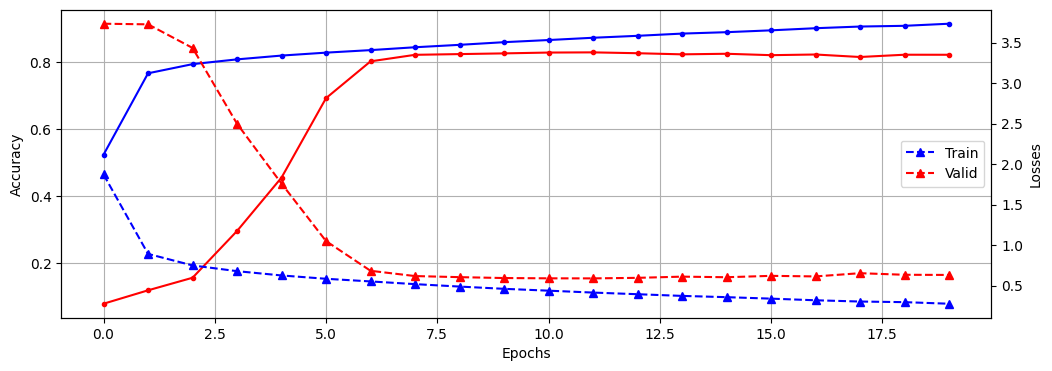

In [85]:
fig, ax1 = plt.subplots(figsize=(12, 4))

ax1.plot(history.history['accuracy'], marker='.', c='b', label='Train')
ax1.plot(history.history['val_accuracy'], marker='.', c='r', label='Valid')
ax1.grid()
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')

ax2 = ax1.twinx()
ax2.plot(history.history['loss'], linestyle='--', marker='^', c='b', label='Train')
ax2.plot(history.history['val_loss'], linestyle='--', marker='^', c='r', label='Valid')
ax2.legend(loc='right')
ax2.set_ylabel('Losses')

plt.show()

In [86]:
model.evaluate(test_set)

34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.8165 - loss: 0.6437


[0.6437424421310425, 0.8164862394332886]